In [68]:
# Importando las Librerias
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.feature_extraction import text

In [69]:
df = pd.read_csv('./data/uwu.csv', delimiter=',', encoding="utf-8")

In [70]:
df.head()

,id,rooms,products
0,1,LIVING DORMITORIO DORMITORIO,Televisor Juguera Cama 2 plazas Televisor Escr...
1,2,Dormitorio,Televisor Televisor
2,3,NaN,NaN
3,4,NaN,NaN
4,5,NaN,NaN


In [71]:
## ANALISIS
df['rooms'] = df['rooms'].astype('str')
df['products'] = df['products'].astype('str')

In [72]:
rooms_corpus = ' '.join(df['rooms'])
products_corpus = ' '.join(df['products'])

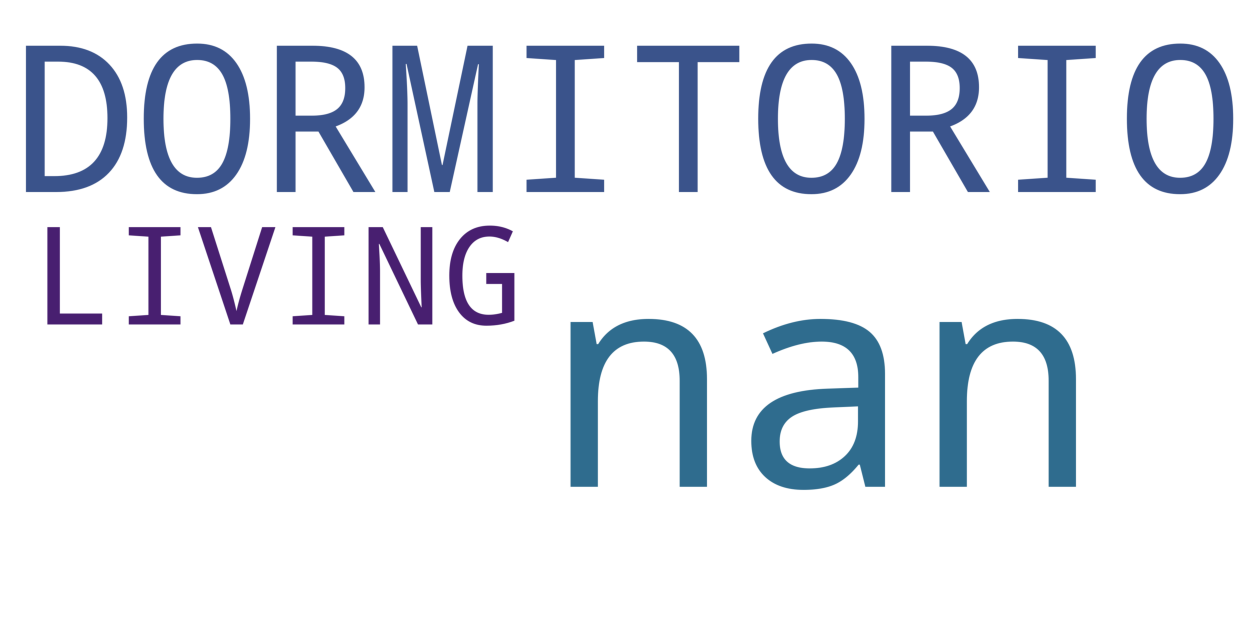

In [73]:
name_wordcloud = WordCloud(stopwords = STOPWORDS, background_color = 'white', height = 2000, width = 4000).generate(rooms_corpus)
plt.figure(figsize = (16,8))
plt.imshow(name_wordcloud)
plt.axis('off')
plt.show()

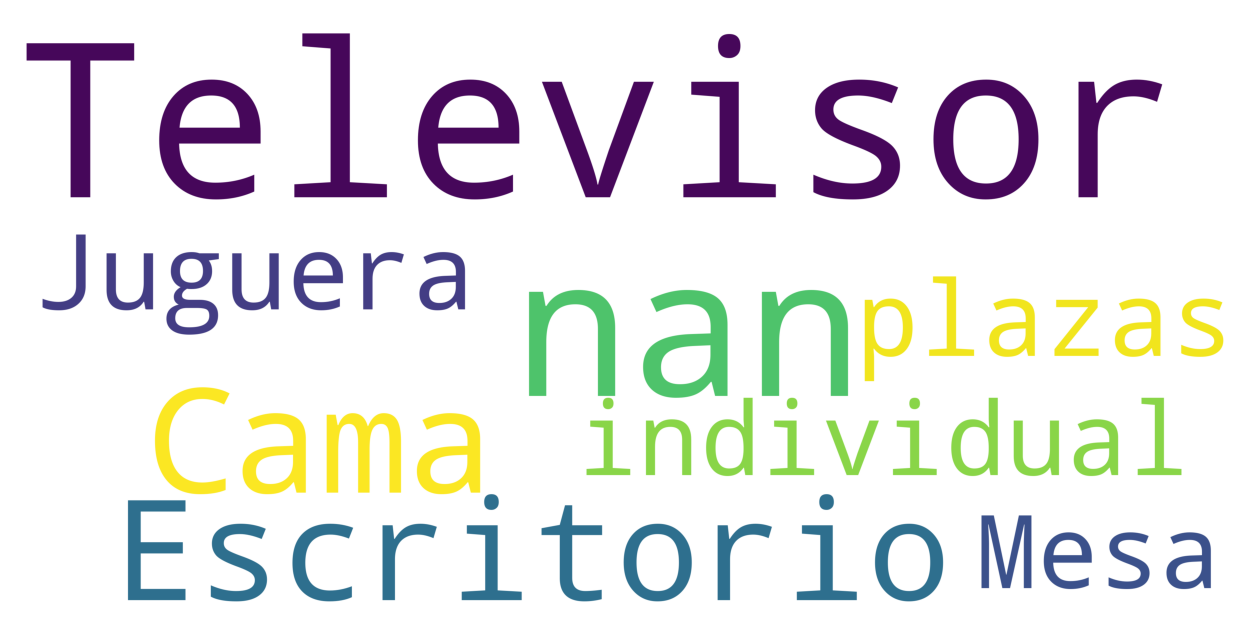

In [74]:
name_wordcloud = WordCloud(stopwords = STOPWORDS, background_color = 'white', height = 2000, width = 4000).generate(products_corpus)
plt.figure(figsize = (16,8))
plt.imshow(name_wordcloud)
plt.axis('off')
plt.show()

In [75]:
# Creamos una columna que contiene la combinacion de columnas productos y salas
df['content'] = df[['rooms', 'products']].astype(str).apply(lambda x: ' // '.join(x), axis = 1)

In [76]:
# Fillna
df['content'].fillna('Null', inplace = True)

In [77]:
# Entrenando el recomendador
my_stop_words = text.ENGLISH_STOP_WORDS.union(["spanish"])
tf = TfidfVectorizer(analyzer = 'word', ngram_range = (1, 2), min_df = 0, stop_words = my_stop_words)
tfidf_matrix = tf.fit_transform(df['content'])

In [78]:
# Similitud de coseno
cosine_similarities = linear_kernel(tfidf_matrix, tfidf_matrix)

In [79]:
results = {}
for idx, row in df.iterrows():
    similar_indices = cosine_similarities[idx].argsort()[:-100:-1]
    similar_items = [(cosine_similarities[idx][i], df['id'][i]) for i in similar_indices]
    results[row['id']] = similar_items[1:]

In [84]:
# Prediction
def item(id):
    name   = df.loc[df['id'] == id]['content'].tolist()[0].split(' // ')[0]
    desc   = ' \nProducts: ' + df.loc[df['id'] == id]['content'].tolist()[0].split(' // ')[1][0:165] + '...'
    prediction = name  + desc
    return prediction

def recommend(item_id, num) -> list:
    recommendations = []
    print('Recommending ' + str(num) + ' dwellings similar to DWELLING ID :' + str(item_id))
    print('---')
    recs = results[item_id][:num]
    for rec in recs:
        print('\nRecommended: Dwelling ' + str(rec[1]) + ' ' + item(rec[1]) + '\n(score:' + str(rec[0]) + ')')
        recommendations.append({'id' : rec[1] , 'score' : round(rec[0],2)})
    return recommendations

In [85]:
recommend(item_id = 1, num = 3)

Recommending 3 dwellings similar to DWELLING ID :1
---

Recommended: Dwelling 2 Dormitorio 
Products: Televisor Televisor...
(score:0.446963098283061)

Recommended: Dwelling 6 nan 
Products: nan...
(score:0.0)

Recommended: Dwelling 5 nan 
Products: nan...
(score:0.0)


[{'id': 2, 'score': 0.45}, {'id': 6, 'score': 0.0}, {'id': 5, 'score': 0.0}]